In [4]:
import pandas as pd

In [5]:
data = {
    'Outlook': ['Sunny','Sunny','Overcast','Rain','Rain','Rain',
                'Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    
    'Humidity': ['High','High','High','High','Normal','Normal',
                 'Normal','High','Normal','Normal','Normal','High','Normal','High'],
    
    'Wind': ['Weak','Strong','Weak','Weak','Weak','Strong',
             'Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    
    'PlayFootball': ['No','No','Yes','Yes','Yes','No',
                     'Yes','No','Yes','Yes','No','Yes','Yes','No']
}

In [6]:
dataset = pd.DataFrame(data)
dataset

,Outlook,Humidity,Wind,PlayFootball
0,Sunny,High,Weak,No
1,Sunny,High,Strong,No
2,Overcast,High,Weak,Yes
3,Rain,High,Weak,Yes
4,Rain,Normal,Weak,Yes
5,Rain,Normal,Strong,No
6,Overcast,Normal,Strong,Yes
7,Sunny,High,Weak,No
8,Sunny,Normal,Weak,Yes
9,Rain,Normal,Weak,Yes


In [7]:
dataset.to_csv('dataset.csv', index=False)
print("dataset.csv file created successfully")

dataset.csv file created successfully


In [8]:
dataset = pd.read_csv('dataset.csv')
dataset

,Outlook,Humidity,Wind,PlayFootball
0,Sunny,High,Weak,No
1,Sunny,High,Strong,No
2,Overcast,High,Weak,Yes
3,Rain,High,Weak,Yes
4,Rain,Normal,Weak,Yes
5,Rain,Normal,Strong,No
6,Overcast,Normal,Strong,Yes
7,Sunny,High,Weak,No
8,Sunny,Normal,Weak,Yes
9,Rain,Normal,Weak,Yes


In [9]:
from sklearn.preprocessing import LabelEncoder

encoders = {}

for col in dataset.columns:
    le = LabelEncoder()
    dataset[col] = le.fit_transform(dataset[col])
    encoders[col] = le

dataset

,Outlook,Humidity,Wind,PlayFootball
0,2,0,1,0
1,2,0,0,0
2,0,0,1,1
3,1,0,1,1
4,1,1,1,1
5,1,1,0,0
6,0,1,0,1
7,2,0,1,0
8,2,1,1,1
9,1,1,1,1


In [10]:
X = dataset[['Outlook','Humidity','Wind']]
y = dataset['PlayFootball']

In [11]:
from sklearn.tree import DecisionTreeClassifier

ct = DecisionTreeClassifier(criterion='entropy')
ct.fit(X, y)

DecisionTreeClassifier(criterion='entropy')

In [12]:
ct

DecisionTreeClassifier(criterion='entropy')

In [13]:
import pandas as pd

# Example: Sunny, High, Strong
sample = pd.DataFrame({
    'Outlook': [encoders['Outlook'].transform(['Sunny'])[0]],
    'Humidity': [encoders['Humidity'].transform(['High'])[0]],
    'Wind': [encoders['Wind'].transform(['Strong'])[0]]
})

prediction = ct.predict(sample)
prediction

array([0])

In [14]:
if prediction[0] == 1:
    print("Prediction: Yes (Play Football)")
else:
    print("Prediction: No (Do Not Play)")

Prediction: No (Do Not Play)


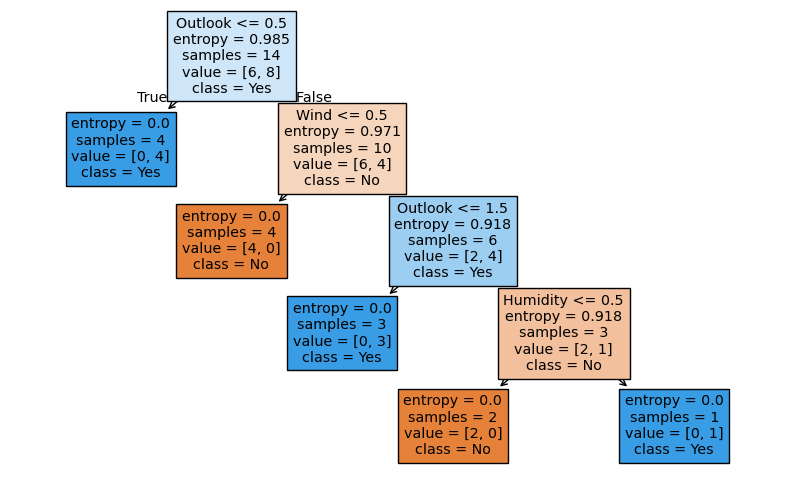

In [15]:
from sklearn import tree
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
tree.plot_tree(ct,
               feature_names=['Outlook','Humidity','Wind'],
               class_names=['No','Yes'],
               filled=True)
plt.show()

In [16]:
from sklearn.metrics import accuracy_score

y_pred = ct.predict(X)
print("Accuracy:", accuracy_score(y, y_pred))

Accuracy: 1.0
